# Riesgo operacional: accidentes laborales por sector

## Resumen

**Decisión:** contextualizar preguntas de prevención y monitoreo HSE por actividad económica. Se compara un indicador descriptivo construido con accidentes sucedidos y afiliaciones-mes; no se estima distribución de pérdidas monetarias.

**Resultado del corte:** El corte contiene 21 sectores; la tasa se recalculó con los numeradores y denominadores publicados.

## Contexto y método

Comparación descriptiva para apoyar preguntas de gestión. No se identifica causalidad ni se valida un modelo productivo.

In [1]:
from pathlib import Path
import hashlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / '03-financial-risk').is_dir())
plt.rcParams.update({'figure.figsize': (9, 4.5), 'axes.grid': True, 'grid.alpha': .2, 'font.size': 10})

## Datos y procedencia

Fuente: [Indicadores de riesgos laborales Minsalud](https://minsalud.gov.co/Proteccion-Social/RiesgosLaborales/Paginas/indicadores.aspx), T3 2026, [companion y método](../../../07-financial-and-construction-risk-lab/02-construction-enterprise-risk/09-construction-safety-and-operational-loss/observed-minsalud-workplace-safety/README.md). La exposición suma afiliaciones mensuales (dependientes, independientes y estudiantes), no trabajadores únicos ni horas. No es una tasa oficial anual.

In [2]:
path = repo / '03-financial-risk/07-financial-and-construction-risk-lab/02-construction-enterprise-risk/09-construction-safety-and-operational-loss/observed-minsalud-workplace-safety/data/sector_safety_indicators_2026q3.csv'
df=pd.read_csv(path)
assert (df.affiliation_months > 0).all()
df['tasa_recalculada'] = 10000 * df.work_accidents_occurred / df.affiliation_months
assert (df.tasa_recalculada.sub(df.accidents_per_10000_affiliation_months).abs() < .00001).all()
print('Sectores:',len(df),'| SHA-256 agregado:',hashlib.sha256(path.read_bytes()).hexdigest())
cols=['sector','work_accidents_occurred','affiliation_months','tasa_recalculada']
display(df[cols].sort_values('tasa_recalculada',ascending=False).head(10).round(2))

Sectores: 21 | SHA-256 agregado: a0b37dcfbbe37830903c78e51795d5454cd68408626f31b462b202eb8daee6ee


,sector,work_accidents_occurred,affiliation_months,tasa_recalculada
9,"AGRICULTURA, GANADERIA, CAZA, SILVICULTURA Y P...",14196,1487804,95.42
13,DISTRIBUCION DE AGUA; EVACUACION Y TRATAMIENTO...,2883,350512,82.25
15,EXPLOTACION DE MINAS Y CANTERAS,3727,536669,69.45
16,INDUSTRIAS MANUFACTURERAS,24339,4297833,56.63
10,ALOJAMIENTO Y SERVICIOS DE COMIDA,5389,1131125,47.64
20,TRANSPORTE Y ALMACENAMIENTO,10441,2570106,40.62
12,CONSTRUCCION,14666,3772481,38.88
1,ACTIVIDADES DE ATENCION DE LA SALUD HUMANA Y D...,9958,2784666,35.76
19,"SUMINISTRO DE ELECTRICIDAD, GAS, VAPOR Y AIRE ...",513,143539,35.74
0,"ACTIVIDADES ARTISTICAS, DE ENTRETENIMIENTO Y R...",1355,403248,33.60


## Resultados

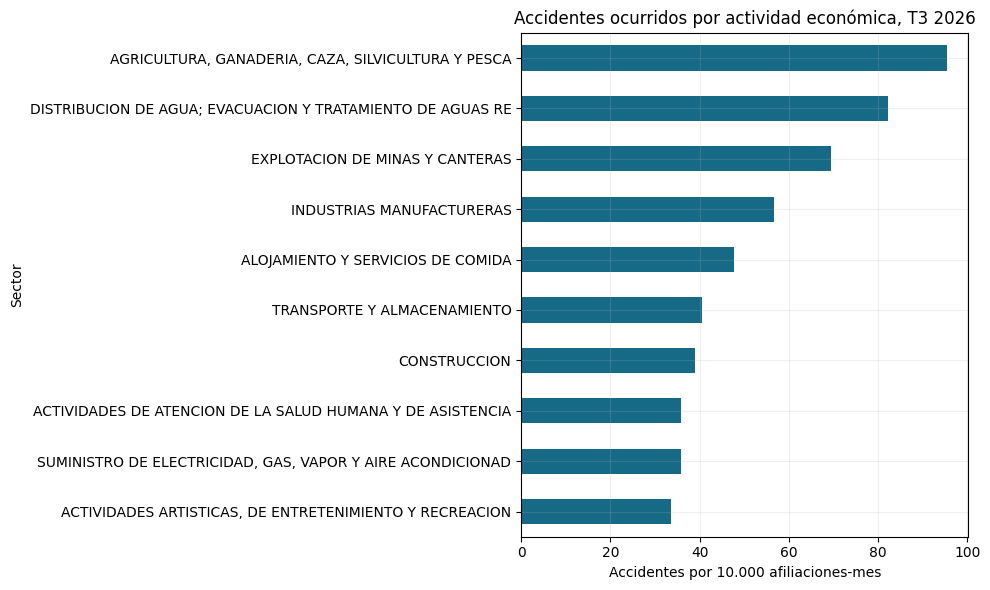

In [3]:
top=df.sort_values('tasa_recalculada',ascending=False).head(10).copy(); top['sector']=top.sector.str.slice(0,58); ax=top.plot.barh(x='sector',y='tasa_recalculada',legend=False,color='#176a86',figsize=(10,6)); ax.invert_yaxis(); ax.set(title='Accidentes ocurridos por actividad económica, T3 2026',xlabel='Accidentes por 10.000 afiliaciones-mes',ylabel='Sector'); plt.tight_layout(); plt.show()

### Sensibilidad al denominador y tamaño de exposición

La tasa compara accidentes ocurridos con afiliaciones-mes. El agregado de todos los sectores se calcula sumando numeradores y denominadores, y no como promedio simple de las tasas.

Total: 137,016 accidentes / 41,909,067 afiliaciones-mes = 32.69 por 10.000 afiliaciones-mes.
Media simple de tasas sectoriales, con igual peso por sector: 35.23.


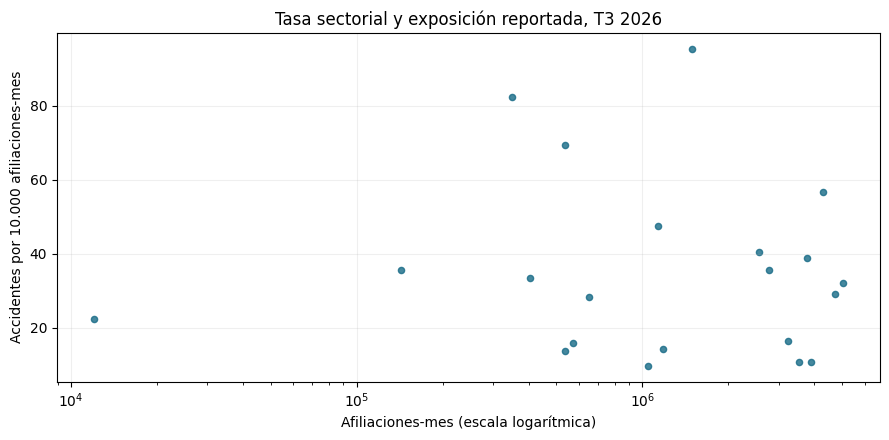

In [4]:
assert df.sector.notna().all() and df.sector.is_unique
assert df.work_accidents_occurred.notna().all() and (df.work_accidents_occurred >= 0).all()
assert df.affiliation_months.notna().all() and (df.affiliation_months > 0).all()
num=df.work_accidents_occurred.sum(); den=df.affiliation_months.sum()
print(f'Total: {num:,.0f} accidentes / {den:,.0f} afiliaciones-mes = {10000*num/den:.2f} por 10.000 afiliaciones-mes.')
print(f'Media simple de tasas sectoriales, con igual peso por sector: {df.tasa_recalculada.mean():.2f}.')
ax=df.plot.scatter(x='affiliation_months',y='tasa_recalculada',color='#176a86',alpha=.8,figsize=(9,4.5)); ax.set_xscale('log');ax.set(title='Tasa sectorial y exposición reportada, T3 2026',xlabel='Afiliaciones-mes (escala logarítmica)',ylabel='Accidentes por 10.000 afiliaciones-mes');plt.tight_layout();plt.show()

Las diferencias entre el promedio agregado y el promedio simple se deben a ponderaciones distintas. Las afiliaciones-mes no son personas únicas y el agregado no representa una empresa ni una frecuencia individual.

## Variante de frecuencia: escenario Poisson ilustrativo

[NIST](https://www.itl.nist.gov/div898/handbook/eda/section3/eda366j.htm) define Poisson para un conteo con media λ. Aplicamos la tasa agregada del corte a exposiciones hipotéticas de 10, 100 y 1.000 afiliaciones-mes: λ = accidentes/afiliaciones-mes × exposición y P(N≥1)=1−exp(−λ). El modelo **supone** intensidad constante e independencia y trata afiliaciones-mes como exposición homogénea; estos supuestos no se validan con un único corte ni tienen en cuenta severidad, cobertura informal o subregistro. No es probabilidad de lesión de una persona ni pronóstico para una empresa. La [OIT](https://ilostat.ilo.org/databases/osh/description/) distingue la tasa de incidencia por trabajadores y señala la diversidad de fuentes; nuestro denominador de afiliaciones-mes no es esa tasa.

,afiliaciones_mes_hipoteticas,lambda_esperado,p_al_menos_un_accidente_modelo
0,10,0.03269,0.03216
1,100,0.32694,0.27887
2,1000,3.26936,0.96197


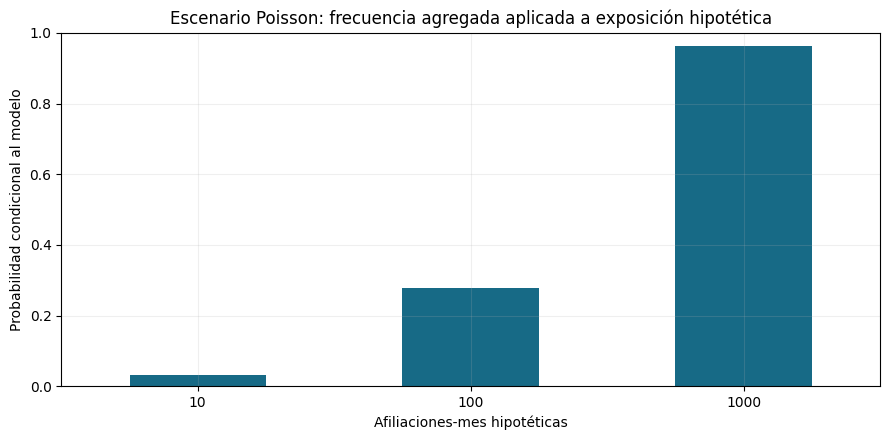

In [5]:
import numpy as np
tasa_agregada = df.work_accidents_occurred.sum() / df.affiliation_months.sum()
escenarios = pd.DataFrame({'afiliaciones_mes_hipoteticas':[10,100,1000]})
escenarios['lambda_esperado'] = tasa_agregada * escenarios.afiliaciones_mes_hipoteticas
escenarios['p_al_menos_un_accidente_modelo'] = -np.expm1(-escenarios.lambda_esperado)
assert escenarios.p_al_menos_un_accidente_modelo.between(0,1).all()
assert escenarios.p_al_menos_un_accidente_modelo.is_monotonic_increasing
display(escenarios.round(5))
ax=escenarios.plot.bar(x='afiliaciones_mes_hipoteticas', y='p_al_menos_un_accidente_modelo', legend=False, color='#176a86');ax.set(title='Escenario Poisson: frecuencia agregada aplicada a exposición hipotética',xlabel='Afiliaciones-mes hipotéticas',ylabel='Probabilidad condicional al modelo',ylim=(0,1));plt.xticks(rotation=0);plt.tight_layout();plt.show()

### Sensibilidad de la intensidad

Para 100 afiliaciones-mes se compara la tasa agregada con intensidades hipotéticas de 0,5 y 2 veces la base. Estos factores son escenarios elegidos, no intervalos de confianza ni cambios estimados. La variación muestra cuánto depende la probabilidad de Poisson de una intensidad supuesta.

In [6]:
factores = pd.DataFrame({'factor_tasa':[0.5, 1.0, 2.0]})
factores['lambda_100'] = 100 * tasa_agregada * factores.factor_tasa
factores['p_al_menos_un_evento_condicional'] = -np.expm1(-factores.lambda_100)
assert factores.p_al_menos_un_evento_condicional.is_monotonic_increasing
display(factores.round(5))

,factor_tasa,lambda_100,p_al_menos_un_evento_condicional
0,0.5,0.16347,0.15081
1,1.0,0.32694,0.27887
2,2.0,0.65387,0.47997


## Interpretación y límites

Las diferencias no identifican causas y la mezcla de ocupaciones varía por sector. Para una distribución de pérdidas se necesitan eventos internos, exposición, costos, severidad y fechas; este corte no permite calibrar frecuencia ni severidad individual.

**Reproducción:** desde este repositorio ejecutar `python -m jupyter nbconvert --execute --to notebook --inplace 01_contexto_accidentalidad.ipynb` en la carpeta del proyecto; requiere Python, pandas, matplotlib, nbformat, nbclient e ipykernel.